# Entrega 2: primeira versão do backtest

Estratégia da Entrega 1 contra o Ibovespa, de jan/2011 a out/2026.

| Bloco | Peso | Rebalanceamento | Regra |
|---|---|---|---|
| Defensivo | 65% | trimestral | nota Quality + Low Vol → 30% melhores → entre elas, 50% mais baratas (L/P) |
| Agressivo | 35% | mensal | 30% menores (Size) → entre elas, 30% com maior Momentum 12-1 |

- **Universo:** as ~86 ações mais líquidas (aproxima o Ibovespa), uma classe por empresa.
- **Pesos:** iguais dentro de cada bloco. A carteira volta para 65/35 a cada trimestre.
- **Hipóteses desta versão:** sem custo de transação; compra no fechamento do dia do sinal; a base não tem ações canceladas (viés de sobrevivência, ver `contexto.md`).

Para rodar: *Run All* (menos de 1 minuto). Precisa dos parquets em `data/processed/`. O código está em `src/`; este notebook só chama as funções e mostra o resultado.

In [1]:
import sys
from pathlib import Path

import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ / "src"))

from dados import carregar_dados
from estrategia import rodar_estrategia
from graficos import acumulado, aplicar_estilo, piores_quedas, retornos_anuais, underwater
from metricas import formatar, periodos_drawdown, resumo

aplicar_estilo()
dados = carregar_dados()

## 1. Rodar a estratégia

In [2]:
res = rodar_estrategia(dados)

periodo = res.carteira.index
retornos = pd.DataFrame({
    "Estratégia 65/35": res.carteira,
    "Bloco defensivo": res.defensivo.retornos,
    "Bloco agressivo": res.agressivo.retornos,
    "Ibovespa": dados.ibov.reindex(periodo),
    "CDI": dados.cdi.reindex(periodo),
})
print(f"{periodo[0]:%d/%m/%Y} a {periodo[-1]:%d/%m/%Y}: {len(periodo):,} pregões")
print(f"Rebalanceamentos: {len(res.defensivo.carteiras)} do defensivo, {len(res.agressivo.carteiras)} do agressivo")

03/01/2011 a 23/10/2026: 3,923 pregões
Rebalanceamentos: 64 do defensivo, 190 do agressivo


## 2. Métricas (Aula 2)

Sharpe e alpha descontam o CDI. Beta, alpha e correlação são medidos contra o Ibovespa. As contas estão em `src/metricas.py`.

In [3]:
formatar(resumo(retornos, dados.cdi, benchmark="Ibovespa"))

,Estratégia 65/35,Bloco defensivo,Bloco agressivo,Ibovespa,CDI
Retorno acumulado,445.3%,749.1%,77.0%,195.9%,346.4%
CAGR,11.33%,14.49%,3.68%,7.11%,9.93%
Volatilidade (anual),21.4%,19.4%,31.6%,23.1%,0.2%
Sharpe (CDI),0.17,0.31,-0.03,0.00,—
Max drawdown,-47.1%,-36.1%,-67.7%,-47.7%,0.0%
Maior drawdown (dias),1219,765,2348,2424,—
Beta,0.80,0.73,0.95,1.00,-0.00
Alpha (anual),3.55%,5.98%,-0.90%,0.00%,0.00%
Correlação,0.87,0.87,0.70,1.00,-0.00


## 3. Gráficos

### Retorno acumulado

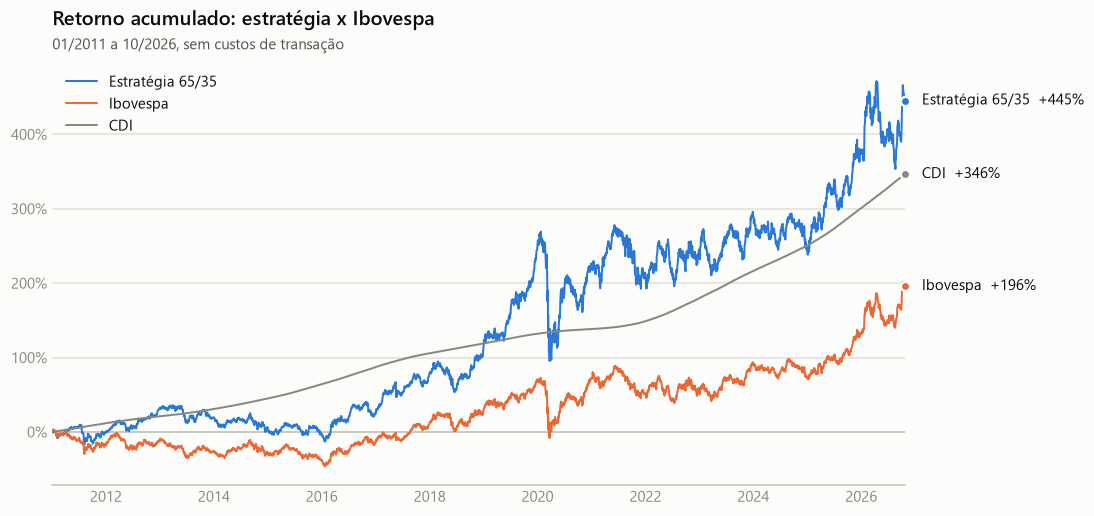

In [4]:
acumulado(retornos[["Estratégia 65/35", "Ibovespa", "CDI"]],
          "Retorno acumulado: estratégia x Ibovespa",
          f"{periodo[0]:%m/%Y} a {periodo[-1]:%m/%Y}, sem custos de transação");

### Drawdown

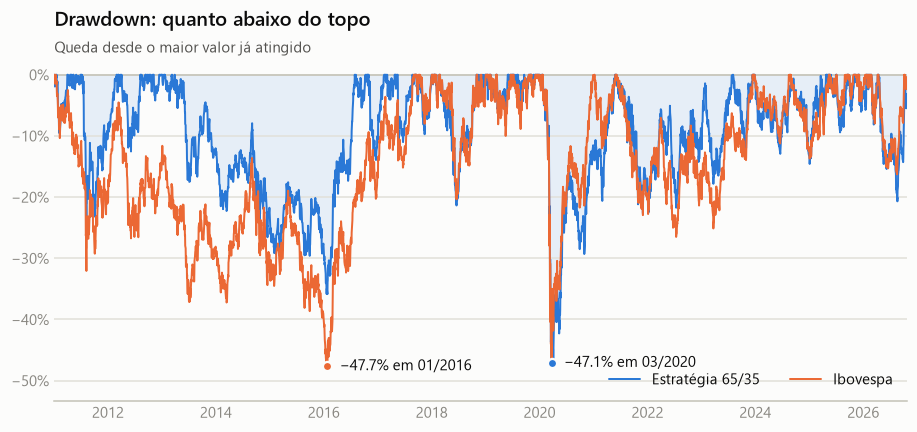

In [5]:
underwater(retornos[["Estratégia 65/35", "Ibovespa"]],
           "Drawdown: quanto abaixo do topo",
           "Queda desde o maior valor já atingido");

### As 5 piores quedas da estratégia

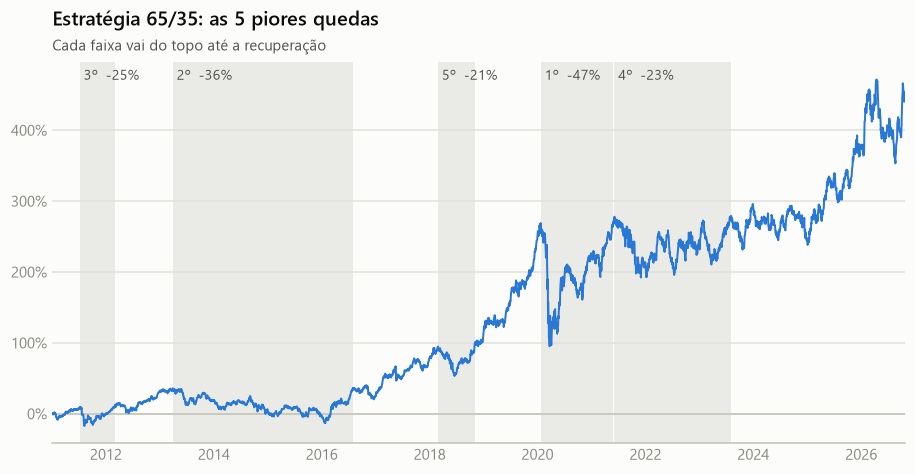

In [6]:
piores_quedas(retornos["Estratégia 65/35"],
              "Estratégia 65/35: as 5 piores quedas",
              "Cada faixa vai do topo até a recuperação");

In [7]:
quedas = periodos_drawdown(retornos["Estratégia 65/35"]).head(5)
quedas.index = quedas.index + 1
quedas.style.format({
    "topo": "{:%d/%m/%Y}",
    "fundo": "{:%d/%m/%Y}",
    "recuperação": lambda d: "não recuperou" if pd.isna(d) else f"{d:%d/%m/%Y}",
    "queda": "{:.1%}",
})

,topo,fundo,recuperação,queda,dias
1,23/01/2020,23/03/2020,26/05/2021,-47.1%,489
2,28/03/2013,26/01/2016,29/07/2016,-35.8%,1219
3,08/07/2011,08/08/2011,28/02/2012,-24.6%,235
4,04/06/2021,01/12/2021,02/08/2023,-22.7%,789
5,26/02/2018,18/06/2018,01/11/2018,-21.4%,248


### Por bloco

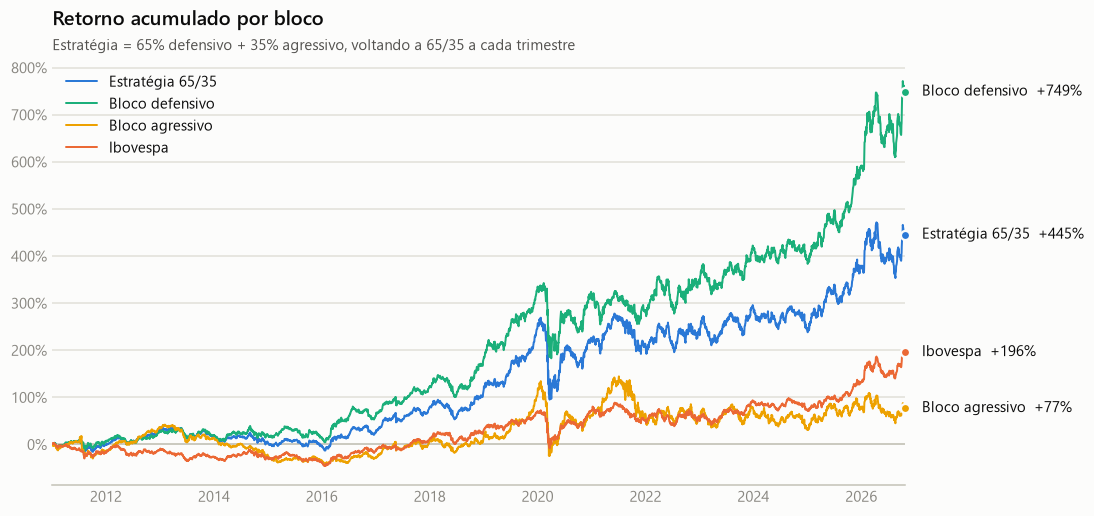

In [8]:
acumulado(retornos[["Estratégia 65/35", "Bloco defensivo", "Bloco agressivo", "Ibovespa"]],
          "Retorno acumulado por bloco",
          "Estratégia = 65% defensivo + 35% agressivo, voltando a 65/35 a cada trimestre");

### Retorno por ano

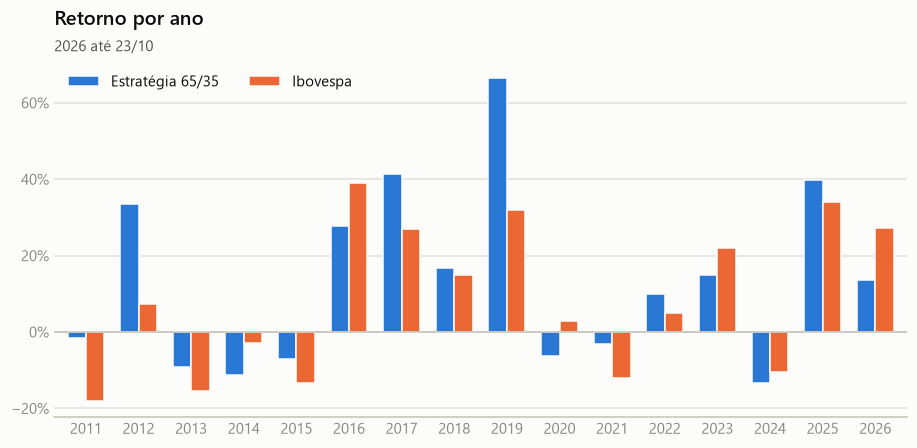

In [9]:
retornos_anuais(retornos[["Estratégia 65/35", "Ibovespa"]],
                "Retorno por ano",
                f"{periodo[-1].year} até {periodo[-1]:%d/%m}");

In [10]:
anual = (1 + retornos).groupby(retornos.index.year).prod() - 1
anual.index.name = "ano"
anual.style.format("{:.1%}")

,Estratégia 65/35,Bloco defensivo,Bloco agressivo,Ibovespa,CDI
ano,,,,,
2011,-1.5%,4.8%,-13.9%,-18.1%,11.6%
2012,33.5%,20.7%,59.5%,7.4%,8.4%
2013,-9.1%,-5.2%,-16.7%,-15.5%,8.1%
2014,-11.4%,0.9%,-31.4%,-2.9%,10.8%
2015,-7.1%,-4.1%,-14.7%,-13.3%,13.2%
2016,27.6%,38.4%,6.7%,38.9%,14.0%
2017,41.3%,38.5%,46.1%,26.9%,10.0%
2018,16.8%,24.5%,2.7%,15.0%,6.4%
2019,66.6%,54.5%,89.2%,31.9%,6.0%


## 4. Carteiras

In [11]:
for nome, bloco in [("Defensivo", res.defensivo), ("Agressivo", res.agressivo)]:
    n_acoes = pd.Series({data: len(tickers) for data, tickers in bloco.carteiras.items()})
    frequencia = pd.Series([t for tickers in bloco.carteiras.values() for t in tickers]).value_counts()
    ultima = max(bloco.carteiras)
    print(f"{nome}: {n_acoes.min()} a {n_acoes.max()} ações por carteira")
    print(f"  última carteira ({ultima:%d/%m/%Y}): {', '.join(bloco.carteiras[ultima])}")
    print(f"  mais frequentes (nº de rebalanceamentos): "
          f"{', '.join(f'{t} ({q})' for t, q in frequencia.head(8).items())}")

Defensivo: 11 a 13 ações por carteira
  última carteira (30/09/2026): POMO4, PETR4, CMIG4, ISAE4, CURY3, BBDC4, PSSA3, BBSE3, CPFE3, VBBR3, TAEE11, ITSA4
  mais frequentes (nº de rebalanceamentos): ITSA4 (59), TAEE11 (45), PSSA3 (43), ITUB4 (39), ISAE4 (37), BRAP4 (28), EGIE3 (28), VALE3 (27)
Agressivo: 6 a 7 ações por carteira
  última carteira (30/09/2026): JHSF3, USIM5, BRAP4, TEND3, IRBR3, SLCE3, CURY3
  mais frequentes (nº de rebalanceamentos): TEND3 (55), DIRR3 (54), BEEF3 (52), SLCE3 (50), AZZA3 (46), VLID3 (38), ABCB4 (35), MOVI3 (34)


## 5. Escolhas em aberto: P3 e método das notas

Duas escolhas do bloco defensivo ficaram em aberto, e rodamos as 4 combinações:

- **Método da nota:** `rank` (percentil de 0 a 1) ou `zscore` (cortado em ±3).
- **Patrimônio líquido negativo (P3):** `excluir` do ranking ou dar a `pior_nota` de Quality.

Só o bloco defensivo muda: o agressivo é igual nas 4. O padrão do código é `rank / excluir`.

**Cuidado:** escolher a combinação só porque rendeu mais no backtest é *overfitting*. Nesse caso, o resultado passa a medir a escolha feita olhando o passado, e não a estratégia. A escolha deve vir do argumento econômico. Esta tabela serve para mostrar o quanto o resultado depende dela.

In [12]:
variantes, diferenca = {}, {}
for metodo in ["rank", "zscore"]:
    for pl_negativo in ["excluir", "pior_nota"]:
        nome = f"{metodo} / {pl_negativo}"
        v = rodar_estrategia(dados, metodo=metodo, pl_negativo=pl_negativo)
        variantes[nome] = v.carteira
        # Em quantos trimestres a carteira defensiva saiu diferente da do padrão
        diferenca[nome] = pd.Series([set(v.defensivo.carteiras[d]) != set(res.defensivo.carteiras[d])
                                     for d in res.defensivo.carteiras]).mean()
variantes["Ibovespa"] = retornos["Ibovespa"]

comparacao = formatar(resumo(pd.DataFrame(variantes), dados.cdi, benchmark="Ibovespa"))
comparacao = comparacao.loc[["CAGR", "Volatilidade (anual)", "Sharpe (CDI)", "Max drawdown", "Alpha (anual)"]]
comparacao.loc["Trimestres com defensivo diferente do padrão"] = [
    f"{diferenca[c]:.0%}" if c in diferenca else "—" for c in comparacao.columns]
comparacao

,rank / excluir,rank / pior_nota,zscore / excluir,zscore / pior_nota,Ibovespa
CAGR,11.33%,11.00%,11.81%,11.68%,7.11%
Volatilidade (anual),21.4%,21.4%,21.3%,21.3%,23.1%
Sharpe (CDI),0.17,0.15,0.19,0.18,0.00
Max drawdown,-47.1%,-47.1%,-48.6%,-48.6%,-47.7%
Alpha (anual),3.55%,3.25%,3.98%,3.86%,0.00%
Trimestres com defensivo diferente do padrão,0%,17%,92%,94%,—
